In [1]:
import numpyro

numpyro.set_host_device_count(4)

In [ ]:
import arviz as az
import corner
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
from numpyro.diagnostics import print_summary
from numpyro.infer import MCMC, NUTS, init_to_value

In [4]:
other_measurements = {
    "Poggio young giants": {
        "h_w0": 0.012,
        "R_w": 5.5,
        "alpha_w": 1.9,
        "phiLON0": 0.1,
        "R_t": 12.1,
        "beta_w": 9.9,
        "R_range": (9.0, 14.5),
    },
    "Poggio Cepheids": {
        "h_w0": 0.057,
        "R_w": 7.7,
        "alpha_w": 1.3,
        "phiLON0": 0.9,
        "R_t": 12.6,
        "beta_w": 8.0,
        "R_range": (9.0, 16.5),
    },
}

## For plotting:

In [5]:
labels_map = {
    "h_w0": r"$h_{w}(R_\odot)$ [kpc]",
    "h_w12": r"$h_{w}(12\,{\rm kpc})$ [kpc]",
    "z_off": r"$z_{\rm off}$ [kpc]",
    "s": r"$s$ [kpc]",
    "R_w": r"$R_w$ [kpc]",
    "alpha_w": r"$\alpha_w$",
    "phiLON0": r"$\phi_{\rm LON,0}$ [deg]",
    "R_t": r"$R_t$ [kpc]",
    "beta_w": r"$\beta_w$ [deg/kpc]",
}

In [13]:
def corner_plot(samples, names=None, color=None, **kwargs):
    """1- and 2-sigma filled contours, no scatter points; pass fig= to overplot."""
    kwargs = {
        "show_titles": True,
        "quantiles": [0.16, 0.5, 0.84],
        **kwargs,
    }
    if names is None:
        names = list(samples.keys())
    with plt.rc_context({"figure.constrained_layout.use": False}):
        return corner.corner(
            np.stack([samples[k] for k in names], axis=-1),
            labels=[labels_map.get(k, "") for k in names],
            color=color,
            levels=1 - np.exp(-0.5 * np.array([1.0, 2.0]) ** 2),
            smooth=1.0,
            bins=40,
            plot_datapoints=False,
            fill_contours=True,
            hist_kwargs={"density": True, "lw": 1.5},
            title_fmt=".3g",
            max_n_ticks=4,
            **kwargs,
        )

## Model parts:

In [ ]:
# I found that normalizing the ampltude at 12 kpc (where the warp signal is larger and
# outside of R_w) rather than at R_sun made things easier to sample.
R_norm = 12.0  # kpc

warp_param_names = ["h_w0", "R_w", "alpha_w", "phiLON0", "R_t", "beta_w"]


def warp_amp_phase(R, R_w, alpha_w, phiLON0, h_w0, R_t=None, beta_w=None):
    """Warp amplitude A(R) [kpc] and line of nodes phi_LON(R) [deg].

    A(R) = h [(R - R_w) / (R_norm - R_w)]^alpha_w for R > R_w
         = 0 for R <= R_w
    """
    # Claude says: we need the inner "where()" to keep 0**alpha out of the graph: its
    # gradient wrt alpha is NaN inside R_w, which would break NUTS
    ratio = (R - R_w) / (R_norm - R_w)
    A = jnp.where(ratio > 0, h_w0 * jnp.where(ratio > 0, ratio, 1.0) ** alpha_w, 0.0)
    phiLON = phiLON0 + 0.0 * R  # broadcast to R's shape
    if R_t is not None:
        phiLON = phiLON0 + beta_w * jnp.clip(R - R_t, 0.0)
    return A, phiLON


def warp_z(R, phi, **params):
    """warp height z = A(R) sin(phi - phiLON(R))"""
    A, phiLON = warp_amp_phase(R, **params)
    return A * jnp.sin(phi - jnp.radians(phiLON))


def poggio_h_w0(samples):
    """convert our amplitude parameter to Eloisa's definition."""
    return samples["h_w0"] / (R_norm - samples["R_w"]) ** samples["alpha_w"]


def z_model(R, phi, p):
    """Full model height: m=1 warp + global offset."""
    return warp_z(R, phi, **{k: p[k] for k in warp_param_names if k in p}) + p.get(
        "z_off", 0.0
    )


def sample_warp_params(twisted=False):
    """Sample the m=1 warp parameters and allow toggling the twist."""

    # Mostly uniform priors, but a weak Gaussian prior on phiLON0
    p = {
        "h_w0": numpyro.sample("h_w0", dist.Uniform(1e-4, 2.0)),
        "R_w": numpyro.sample("R_w", dist.Uniform(3.0, R_norm)),
        "alpha_w": numpyro.sample("alpha_w", dist.Uniform(0.1, 5.0)),
        # APW: I changed the prior here to keep it on the same side of the galaxy:
        "phiLON0": numpyro.sample("phiLON0", dist.Normal(0, 45.0)),  # deg
    }
    if twisted:
        # twist starts outside the warp R_w
        p["R_t"] = numpyro.sample("R_t", dist.Uniform(p["R_w"], 16.0))
        p["beta_w"] = numpyro.sample("beta_w", dist.Uniform(-30.0, 30.0))  # deg / kpc
    return p


def model(
    R,
    phi,
    z0_err,
    z0=None,
    twisted=False,
    offset=True,
    jitter=True,
    z_off_fixed=None,
):
    """numpyro model for the warp.

    Set z_off_fixed to a number to fix the global offset, or set offset=True to fit it.
    """
    p = sample_warp_params(twisted=twisted)

    # One global vertical offset, e.g. z_sun
    if z_off_fixed is not None:
        p["z_off"] = numpyro.deterministic("z_off", jnp.asarray(z_off_fixed))
    elif offset:
        p["z_off"] = numpyro.sample("z_off", dist.Normal(0.0, 0.1))

    # intrinsic scatter of the cell z0 values about the smooth model
    sigma = z0_err
    if jitter:
        s = numpyro.sample("s", dist.HalfNormal(0.1))
        sigma = jnp.sqrt(z0_err**2 + s**2)

    numpyro.sample("z0", dist.Normal(z_model(R, phi, p), sigma), obs=z0)

In [8]:
def run_fit(
    data,
    num_warmup=1000,
    num_samples=2000,
    seed=0,
    **model_kwargs,
):
    """Run MCMC/NUTS, return posterior samples.

    Note that the "data" dictionary must contain keys: R, phi, z0, z0_err
    """
    # start every chain at plausible param values
    init = {
        "alpha_w": 1.5,
        "phiLON0": 0.0,
        "z_off": 0.0,
        "s": 0.03,
        "h_w0": 0.3,
        "R_w": 7.0,
    }
    if model_kwargs.get("twisted", False):
        init.update(R_t=11.0, beta_w=0.0)

    mcmc = MCMC(
        NUTS(model, init_strategy=init_to_value(values=init)),
        num_warmup=num_warmup,
        num_samples=num_samples,
        num_chains=4,
    )
    mcmc.run(
        jax.random.PRNGKey(seed),
        **data,
        **model_kwargs,
        extra_fields=("diverging",),
    )
    by_chain = mcmc.get_samples(group_by_chain=True)
    print_summary(by_chain)
    print(f"Number of divergences: {mcmc.get_extra_fields()['diverging'].sum()}")

    samples = mcmc.get_samples()
    return {k: np.asarray(v) for k, v in samples.items()}


In [9]:
_data = np.load("../../from-emma/warp_ring_data_for_adrian.npz")

In [10]:
data = {
    "R": _data["R"],
    "phi": _data["phi_eloisa_rad"],
    "z0": _data["z0"],
    "z0_err": _data["z0_err"],
}

In [18]:
samples_twist = run_fit(
    data,
    num_warmup=1000,
    num_samples=8000,
    seed=0,
    twisted=True
)

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
       R_t     12.08      1.85     12.25      9.45     15.98    563.09      1.00
       R_w      6.51      1.35      6.72      4.32      8.62   5662.70      1.00
   alpha_w      1.63      0.57      1.54      0.73      2.53   5116.27      1.00
    beta_w      4.53      6.20      4.90     -1.13     11.25   2498.98      1.00
      h_w0      0.24      0.02      0.24      0.21      0.28  10890.46      1.00
   phiLON0    -25.85      6.22    -25.11    -34.63    -16.12   3836.21      1.00
         s      0.04      0.00      0.04      0.04      0.05   9142.28      1.00
     z_off     -0.03      0.01     -0.03     -0.05     -0.02  10737.28      1.00

Number of divergences: 146


In [15]:
samples_notwist = run_fit(
    data,
    num_warmup=1000,
    num_samples=8000,
    seed=42,
    twisted=False
)

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
       R_w      6.98      1.20      7.19      5.08      8.74  10078.39      1.00
   alpha_w      1.26      0.44      1.17      0.61      1.95   9861.47      1.00
      h_w0      0.25      0.02      0.25      0.21      0.28  15281.18      1.00
   phiLON0    -19.41      3.31    -19.24    -24.72    -13.88  12019.57      1.00
         s      0.04      0.00      0.04      0.04      0.05  19609.35      1.00
     z_off     -0.03      0.01     -0.03     -0.04     -0.02  17180.86      1.00

Number of divergences: 17


In [19]:
corner_plot(samples_twist)

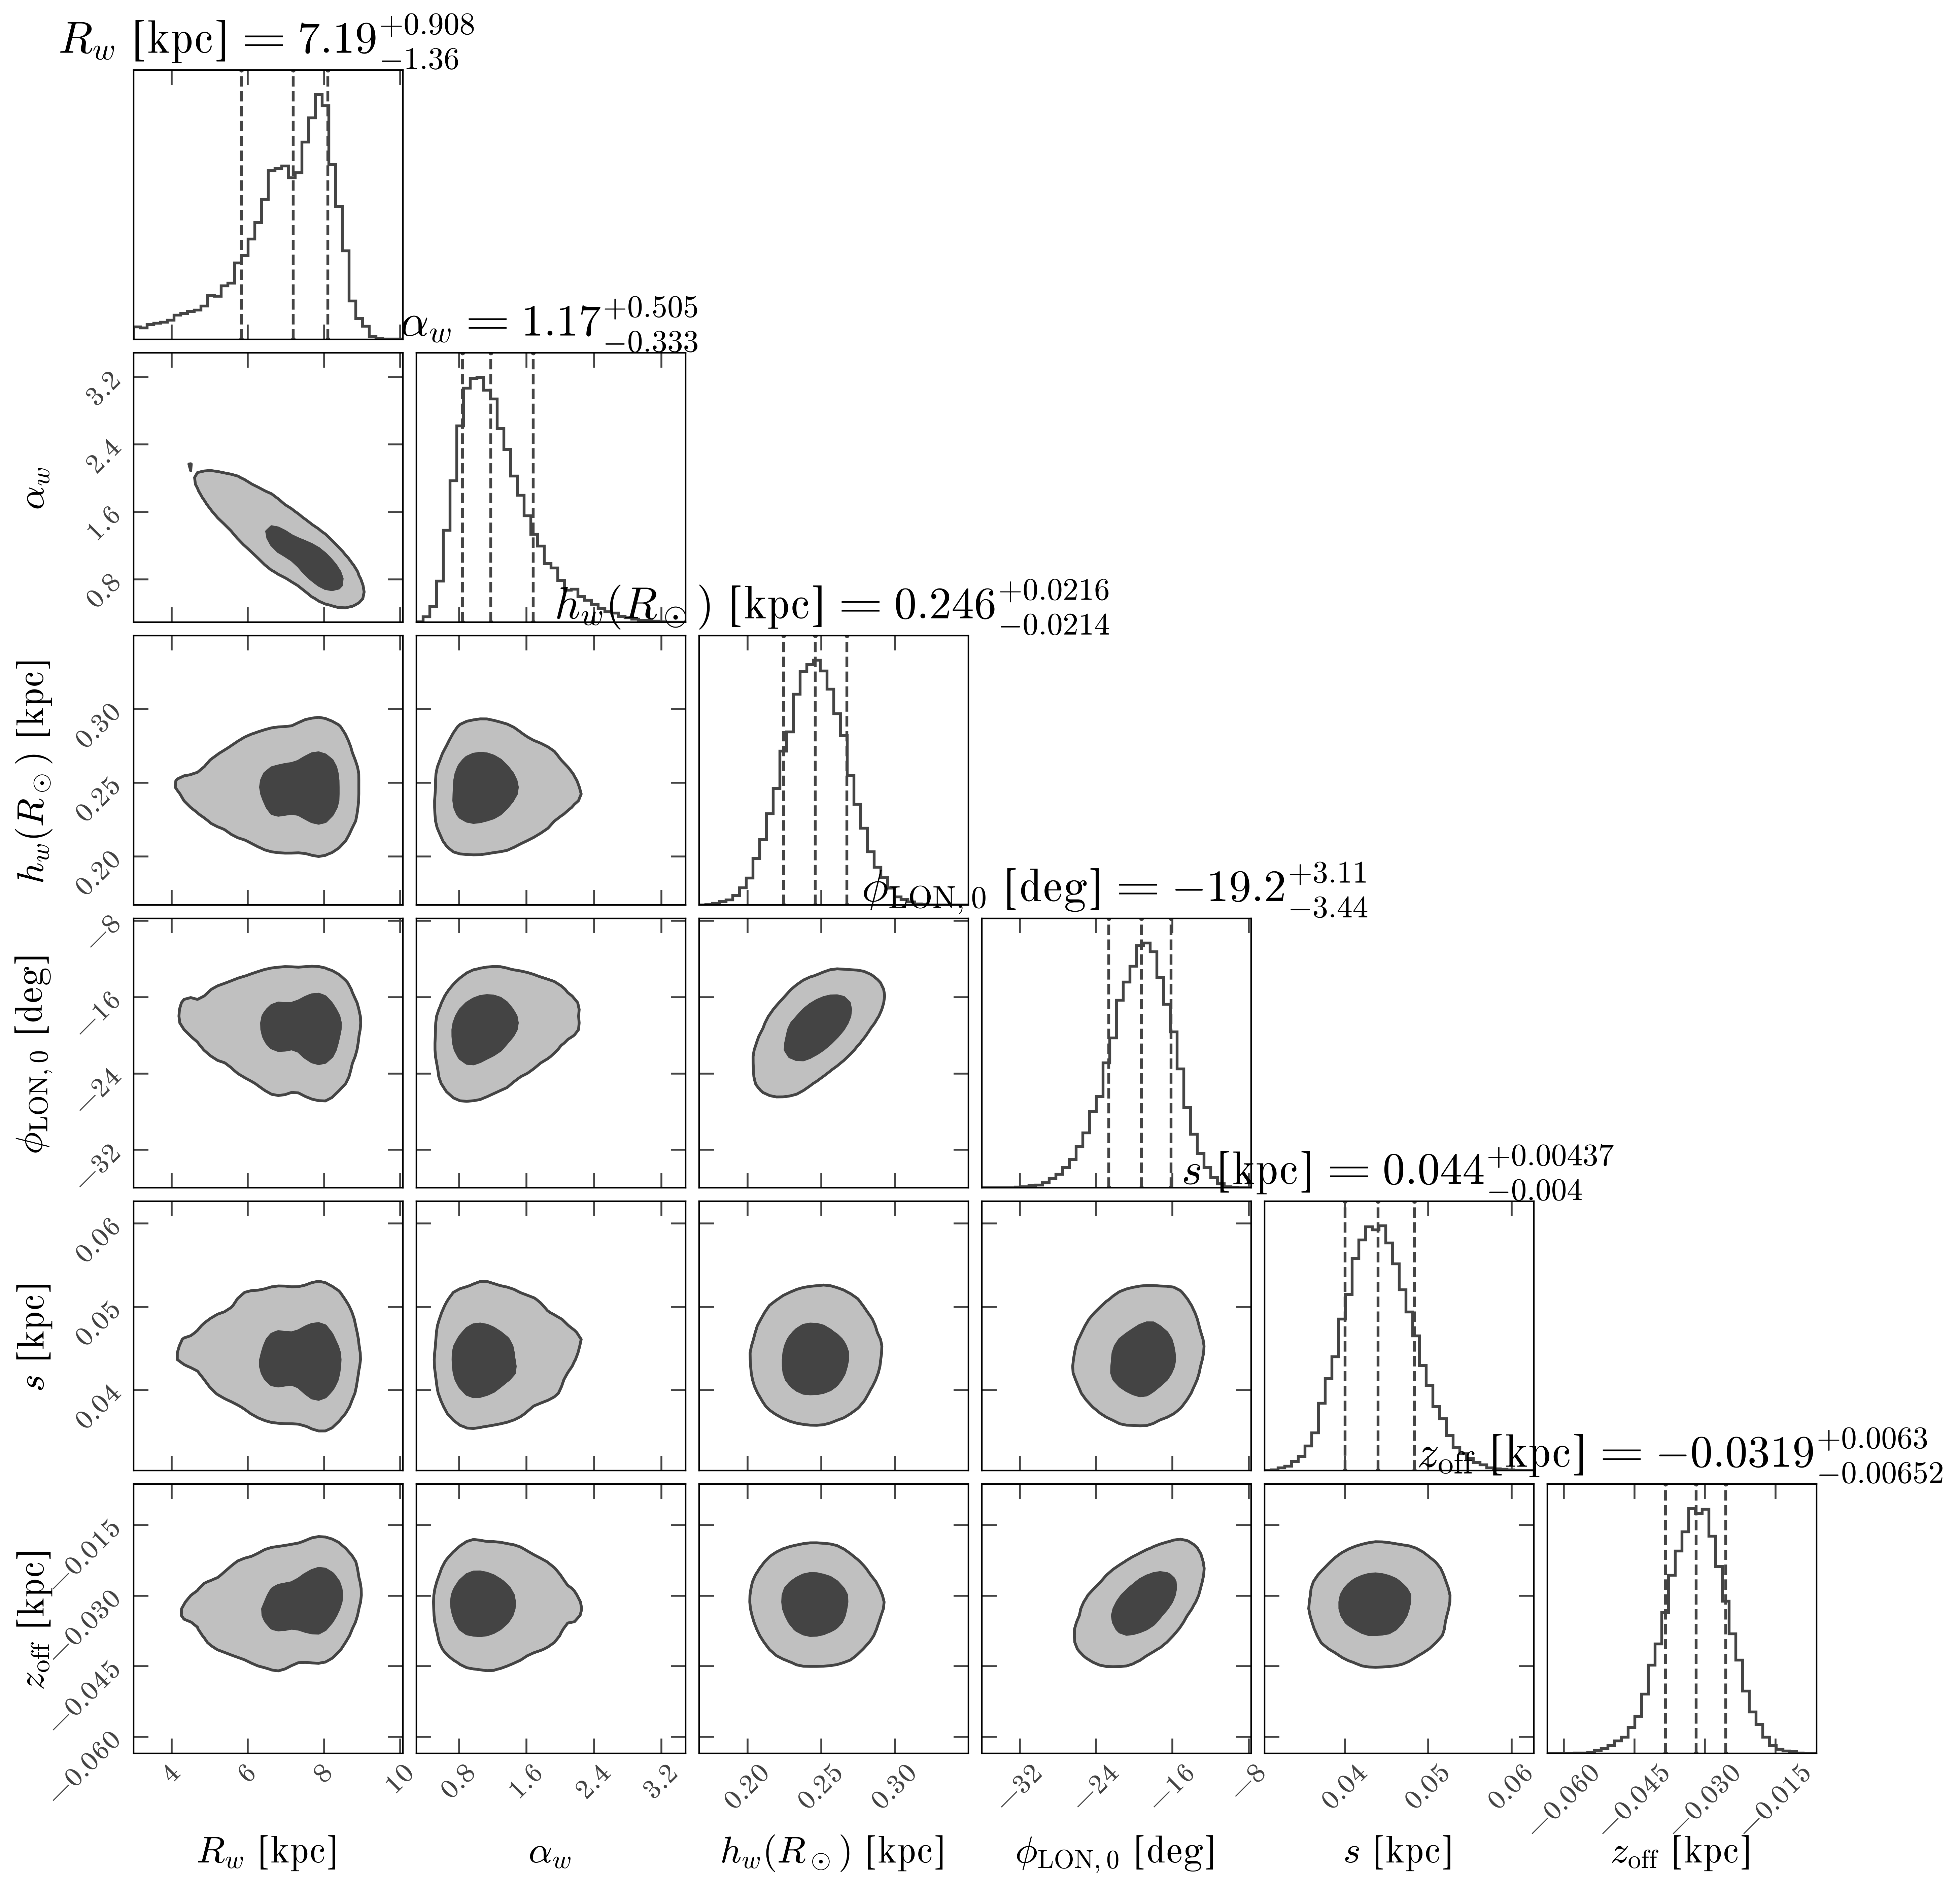

In [17]:
corner_plot(samples_notwist)